In [20]:
import pandas as pd
import numpy as np

# ============================================
# 1. قراءة البيانات وحذف الصف الوصفي
# ============================================
df = pd.read_csv("Yemen Cholera Outbreak Epidemiology Data.csv", skiprows=[1])

# ============================================
# 2. تنظيف الأعمدة والتاريخ
# ============================================
# تحويل التاريخ إلى datetime
df['Date'] = pd.to_datetime(df['Date'])

# ترتيب حسب التاريخ
df = df.sort_values('Date').reset_index(drop=True)

# ============================================
# 3. تحويل البيانات التراكمية إلى حالات جديدة
# ============================================
# حساب الحالات الجديدة (الفرق بين كل تاريخين)
df['New_Cases'] = df['Cases'].diff()
df['New_Deaths'] = df['Deaths'].diff()

# الصف الأول سيكون NaN لأنه لا يوجد تاريخ سابق
df.iloc[0, df.columns.get_loc('New_Cases')] = 0
df.iloc[0, df.columns.get_loc('New_Deaths')] = 0

# ============================================
# 4. التعامل مع القيم السالبة (أخطاء في البيانات)
# ============================================
# أحياناً البيانات التراكمية تُصحح downward، فنحصل على قيم سالبة
df['New_Cases'] = df['New_Cases'].apply(lambda x: max(0, x))
df['New_Deaths'] = df['New_Deaths'].apply(lambda x: max(0, x))

# ============================================
# 5. التجميع الأسبوعي (لتوحيد الدقة الزمنية)
# ============================================
# تعيين التاريخ كـ index
df.set_index('Date', inplace=True)

# تجميع أسبوعي (أسبوع يبدأ يوم الإثنين)
weekly_df = df.resample('W-MON').agg({
    'New_Cases': 'sum',
    'New_Deaths': 'sum',
    'Cases': 'last',  # آخر قيمة تراكمية في الأسبوع
    'Deaths': 'last',
    'CFR (%)': 'mean',
    'Attack Rate (per 1000)': 'mean'
}).reset_index()

# ============================================
# 6. ملء القيم المفقودة
# ============================================
# إذا كان هناك أسابيع بدون تقارير، نملؤها بـ 0 (افترضنا عدم وجود حالات)
weekly_df['New_Cases'] = weekly_df['New_Cases'].fillna(0)
weekly_df['New_Deaths'] = weekly_df['New_Deaths'].fillna(0)

# ============================================
# 7. عرض النتائج
# ============================================
print("=== البيانات الأسبوعية النظيفة ===")
print(weekly_df.head(10))
print(f"\nعدد الأسابيع: {len(weekly_df)}")
print(f"\nالفترة الزمنية: {weekly_df['Date'].min()} إلى {weekly_df['Date'].max()}")
print(f"\nإحصائيات الحالات الجديدة:")
print(weekly_df['New_Cases'].describe())

# حفظ البيانات النظيفة
weekly_df.to_csv('cholera_weekly_cleaned.csv', index=False)
print("\n✅ تم حفظ البيانات النظيفة في: cholera_weekly_cleaned.csv")

=== البيانات الأسبوعية النظيفة ===
        Date  New_Cases  New_Deaths     Cases  Deaths   CFR (%)  \
0 2017-05-22        0.0         0.0   35471.0   361.0  1.000000   
1 2017-05-29    16669.0       110.0   52140.0   471.0  0.900000   
2 2017-06-05    34282.0       210.0   86422.0   681.0  0.800000   
3 2017-06-12    42763.0       261.0  129185.0   942.0  0.733333   
4 2017-06-19    43101.0       228.0  172286.0  1170.0  0.700000   
5 2017-06-26    46512.0       230.0  218798.0  1400.0  0.657143   
6 2017-07-03    50810.0       214.0  269608.0  1614.0  0.600000   
7 2017-07-10    43930.0       118.0  313538.0  1732.0  0.600000   
8 2017-07-17    43053.0        70.0  356591.0  1802.0  0.500000   
9 2017-07-24    39495.0        67.0  396086.0  1869.0  0.500000   

   Attack Rate (per 1000)  
0                1.190000  
1                1.760000  
2                2.555000  
3                3.990000  
4                5.216000  
5                6.742857  
6                8.328571  
7  

In [21]:
import pandas as pd
import numpy as np

# ============================================
# 1. قراءة بيانات الأمطار
# ============================================
rain_df = pd.read_csv('hdx_hapi_rainfall_yem.csv')

print("=== معلومات عامة عن بيانات الأمطار ===")
print(f"عدد الصفوف: {len(rain_df)}")
print(f"الأعمدة: {rain_df.columns.tolist()}")
print(f"\nمستويات الإدارة:")
print(rain_df['admin_level'].value_counts())
print(f"\nفترات التجميع:")
print(rain_df['aggregation_period'].value_counts())

# ============================================
# 2. تصفية البيانات: نريد المستوى الوطني فقط
# ============================================
# نأخذ admin_level = 1 (محافظات) ثم نجمعها وطنياً
# أو إذا كان هناك admin_level = 0 (وطني) نستخدمه مباشرة

# التحقق من وجود بيانات وطنية
national_rain = rain_df[rain_df['admin_level'] == 0].copy()

if len(national_rain) > 0:
    print("\n✅ يوجد بيانات وطنية مباشرة")
    rain_national = national_rain.copy()
else:
    print("\n⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات")
    # نأخذ بيانات المحافظات فقط
    rain_national = rain_df[rain_df['admin_level'] == 1].copy()

# ============================================
# 3. تنظيف التواريخ
# ============================================
# تحويل التواريخ
rain_national['start_date'] = pd.to_datetime(rain_national['reference_period_start'])
rain_national['end_date'] = pd.to_datetime(rain_national['reference_period_end'])

# ============================================
# 4. تصفية الفترة الزمنية (2017-2018 لتطابق الكوليرا)
# ============================================
rain_national = rain_national[
    (rain_national['start_date'] >= '2017-01-01') & 
    (rain_national['end_date'] <= '2018-12-31')
].copy()

print(f"\nعدد السجلات بعد التصفية الزمنية: {len(rain_national)}")

# ============================================
# 5. اختيار الدقة العشرية (dekad) فقط
# ============================================
rain_national = rain_national[rain_national['aggregation_period'] == 'dekad'].copy()

print(f"عدد السجلات العشرية: {len(rain_national)}")

# ============================================
# 6. التجميع على المستوى الوطني
# ============================================
# إذا كانت البيانات على مستوى المحافظات، نجمعها
if 'admin1_name' in rain_national.columns and rain_national['admin_level'].max() == 1:
    # تجميع حسب التاريخ
    rain_national_agg = rain_national.groupby(['start_date', 'end_date']).agg({
        'rainfall': 'mean',  # متوسط الأمطار على مستوى اليمن
        'rainfall_anomaly_pct': 'mean'  # متوسط شذوذ الأمطار
    }).reset_index()
    
    print("\n✅ تم تجميع بيانات المحافظات على المستوى الوطني")
else:
    # البيانات وطنية بالفعل
    rain_national_agg = rain_national[['start_date', 'end_date', 'rainfall', 'rainfall_anomaly_pct']].copy()

# ============================================
# 7. إعادة تسمية الأعمدة
# ============================================
rain_national_agg = rain_national_agg.rename(columns={
    'start_date': 'Date',
    'rainfall': 'rainfall_mm',
    'rainfall_anomaly_pct': 'rainfall_anomaly'
})

# ============================================
# 8. عرض النتائج
# ============================================
print("\n=== بيانات الأمطار الوطنية الأسبوعية ===")
print(rain_national_agg.head(10))
print(f"\nعدد السجلات: {len(rain_national_agg)}")

# حفظ البيانات
rain_national_agg.to_csv('rainfall_national_weekly.csv', index=False)
print("\n✅ تم حفظ بيانات الأمطار في: rainfall_national_weekly.csv")

=== معلومات عامة عن بيانات الأمطار ===
عدد الصفوف: 44742
الأعمدة: ['location_code', 'has_hrp', 'in_gho', 'provider_admin1_name', 'provider_admin2_name', 'admin1_code', 'admin1_name', 'admin2_code', 'admin2_name', 'admin_level', 'provider_admin1_code', 'provider_admin2_code', 'aggregation_period', 'rainfall', 'rainfall_long_term_average', 'rainfall_anomaly_pct', 'number_pixels', 'version', 'reference_period_start', 'reference_period_end']

مستويات الإدارة:
admin_level
2    33390
1    11352
Name: count, dtype: int64

فترات التجميع:
aggregation_period
dekad      14914
1-month    14914
3-month    14914
Name: count, dtype: int64

⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات

عدد السجلات بعد التصفية الزمنية: 0
عدد السجلات العشرية: 0

=== بيانات الأمطار الوطنية الأسبوعية ===
Empty DataFrame
Columns: [Date, end_date, rainfall_mm, rainfall_anomaly]
Index: []

عدد السجلات: 0

✅ تم حفظ بيانات الأمطار في: rainfall_national_weekly.csv


In [22]:
# ============================================
# 1. قراءة بيانات النازحين
# ============================================
idp_df = pd.read_csv('hdx_hapi_idps_yem.csv')

print("=== معلومات عامة عن بيانات النازحين ===")
print(f"عدد الصفوف: {len(idp_df)}")
print(f"الأعمدة: {idp_df.columns.tolist()}")
print(f"\nمستويات الإدارة:")
print(idp_df['admin_level'].value_counts())

# ============================================
# 2. تصفية البيانات: نريد المستوى الوطني
# ============================================
# نحاول أولاً admin_level = 0 (وطني)
idp_national = idp_df[idp_df['admin_level'] == 0].copy()

if len(idp_national) == 0:
    print("\n⚠️ لا يوجد بيانات وطنية، سنجمع المحافظات")
    # نأخذ بيانات المحافظات
    idp_national = idp_df[idp_df['admin_level'] == 1].copy()

# ============================================
# 3. تنظيف التواريخ
# ============================================
idp_national['start_date'] = pd.to_datetime(idp_national['reference_period_start'])
idp_national['end_date'] = pd.to_datetime(idp_national['reference_period_end'])

# ============================================
# 4. تصفية الفترة الزمنية (2017-2018)
# ============================================
idp_national = idp_national[
    (idp_national['start_date'] >= '2017-01-01') & 
    (idp_national['end_date'] <= '2018-12-31')
].copy()

print(f"\nعدد السجلات بعد التصفية الزمنية: {len(idp_national)}")

# ============================================
# 5. التجميع على المستوى الوطني
# ============================================
if 'admin1_name' in idp_national.columns and idp_national['admin_level'].max() == 1:
    # تجميع حسب التاريخ (مجموع النازحين في كل المحافظات)
    idp_national_agg = idp_national.groupby(['start_date', 'end_date']).agg({
        'population': 'sum'  # مجموع النازحين
    }).reset_index()
    
    print("\n✅ تم تجميع بيانات المحافظات على المستوى الوطني")
else:
    # البيانات وطنية بالفعل
    idp_national_agg = idp_national[['start_date', 'end_date', 'population']].copy()

# ============================================
# 6. إعادة تسمية الأعمدة
# ============================================
idp_national_agg = idp_national_agg.rename(columns={
    'start_date': 'Date',
    'population': 'total_idps'
})

# ============================================
# 7. عرض النتائج
# ============================================
print("\n=== بيانات النازحين الوطنية ===")
print(idp_national_agg.head(10))
print(f"\nعدد السجلات: {len(idp_national_agg)}")

# حفظ البيانات
idp_national_agg.to_csv('idps_national.csv', index=False)
print("\n✅ تم حفظ بيانات النازحين في: idps_national.csv")

=== معلومات عامة عن بيانات النازحين ===
عدد الصفوف: 5613
الأعمدة: ['location_code', 'has_hrp', 'in_gho', 'provider_admin1_name', 'provider_admin2_name', 'admin1_code', 'admin1_name', 'admin2_code', 'admin2_name', 'admin_level', 'operation', 'assessment_type', 'population', 'reporting_round', 'reference_period_start', 'reference_period_end']

مستويات الإدارة:
admin_level
2    5146
1     434
0      33
Name: count, dtype: int64

عدد السجلات بعد التصفية الزمنية: 14

=== بيانات النازحين الوطنية ===
         Date   end_date  total_idps
12 2017-02-28 2017-02-28     2006112
13 2017-04-30 2017-04-30     2000010
14 2017-06-30 2017-06-30     1991670
15 2017-09-30 2017-09-30     2026662
16 2017-10-30 2017-10-30      731892
17 2017-11-30 2017-11-30      741036
18 2017-12-31 2017-12-31      761214
19 2018-01-30 2018-01-30      802002
20 2018-02-28 2018-02-28      224460
21 2018-03-30 2018-03-30      592434

عدد السجلات: 14

✅ تم حفظ بيانات النازحين في: idps_national.csv


In [23]:
# ============================================
# 1. قراءة البيانات النظيفة
# ============================================
cholera_weekly = pd.read_csv('cholera_weekly_cleaned.csv')
rain_national = pd.read_csv('rainfall_national_weekly.csv')
idps_national = pd.read_csv('idps_national.csv')

# تحويل التواريخ وتوحيد نوع البيانات لضمان توافق merge_asof
for df in [cholera_weekly, rain_national, idps_national]:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df['Date'] = df['Date'].astype('datetime64[ns]')

# =============================================
# 2. دمج بيانات الكوليرا مع الأمطار
# ============================================
# نستخدم merge_asof لأن التواريخ قد لا تتطابق تماماً
merged_df = pd.merge_asof(
    cholera_weekly.sort_values('Date'),
    rain_national.sort_values('Date'),
    on='Date',
    direction='nearest',
    tolerance=pd.Timedelta('7 days')
)

print(f"\nبعد دمج الأمطار: {len(merged_df)} صف")

# ============================================
# 3. دمج بيانات النازحين
# ============================================
# النازحين قد يكونون على فترات أطول، نستخدم forward fill
merged_df = pd.merge_asof(
    merged_df.sort_values('Date'),
    idps_national.sort_values('Date'),
    on='Date',
    direction='backward',
    tolerance=pd.Timedelta('90 days')
)

print(f"بعد دمج النازحين: {len(merged_df)} صف")

# ============================================
# 4. ملء القيم المفقودة
# ============================================
# إذا لم نجد بيانات أمطار أو نازحين لأسبوع معين، نملأ بالقيمة السابقة
merged_df['rainfall_mm'] = merged_df['rainfall_mm'].ffill()
merged_df['rainfall_anomaly'] = merged_df['rainfall_anomaly'].ffill()
merged_df['total_idps'] = merged_df['total_idps'].ffill()

# إذا بقيت قيم مفقودة في البداية، نملؤها بـ 0
merged_df['rainfall_mm'] = merged_df['rainfall_mm'].fillna(0)
merged_df['rainfall_anomaly'] = merged_df['rainfall_anomaly'].fillna(0)
merged_df['total_idps'] = merged_df['total_idps'].fillna(0)

# ============================================
# 5. عرض النتائج النهائية
# ============================================
print("\n=== البيانات المدمجة النهائية ===")
print(merged_df.head(10))
print(f"\nعدد الصفوف: {len(merged_df)}")
print(f"\nالأعمدة: {merged_df.columns.tolist()}")
print(f"\nالقيم المفقودة:")
print(merged_df.isnull().sum())

# حفظ البيانات المدمجة
merged_df.to_csv('merged_data_final.csv', index=False)
print("\n✅ تم حفظ البيانات المدمجة في: merged_data_final.csv")


بعد دمج الأمطار: 59 صف
بعد دمج النازحين: 59 صف

=== البيانات المدمجة النهائية ===
        Date  New_Cases  New_Deaths     Cases  Deaths   CFR (%)  \
0 2017-05-22        0.0         0.0   35471.0   361.0  1.000000   
1 2017-05-29    16669.0       110.0   52140.0   471.0  0.900000   
2 2017-06-05    34282.0       210.0   86422.0   681.0  0.800000   
3 2017-06-12    42763.0       261.0  129185.0   942.0  0.733333   
4 2017-06-19    43101.0       228.0  172286.0  1170.0  0.700000   
5 2017-06-26    46512.0       230.0  218798.0  1400.0  0.657143   
6 2017-07-03    50810.0       214.0  269608.0  1614.0  0.600000   
7 2017-07-10    43930.0       118.0  313538.0  1732.0  0.600000   
8 2017-07-17    43053.0        70.0  356591.0  1802.0  0.500000   
9 2017-07-24    39495.0        67.0  396086.0  1869.0  0.500000   

   Attack Rate (per 1000) end_date_x rainfall_mm rainfall_anomaly  end_date_y  \
0                1.190000        NaN           0                0  2017-04-30   
1                

In [24]:
# ============================================
# 1. قراءة البيانات المدمجة
# ============================================
df = pd.read_csv('merged_data_final.csv')
df['Date'] = pd.to_datetime(df['Date'])

# ============================================
# 2. إنشاء Lag Features (القيم المتأخرة)
# ============================================
# عدد الحالات في الأسبوع السابق
df['cases_lag_1'] = df['New_Cases'].shift(1)
df['cases_lag_2'] = df['New_Cases'].shift(2)
df['cases_lag_3'] = df['New_Cases'].shift(3)
df['cases_lag_4'] = df['New_Cases'].shift(4)

# ============================================
# 3. إنشاء Rolling Statistics (الإحصائيات المتحركة)
# ============================================
# متوسط الحالات خلال آخر 4 أسابيع
df['cases_rolling_mean_4'] = df['New_Cases'].rolling(window=4).mean()

# متوسط الحالات خلال آخر 8 أسابيع
df['cases_rolling_mean_8'] = df['New_Cases'].rolling(window=8).mean()

# ============================================
# 4. إنشاء ميزات الأمطار المتأخرة
# ============================================
# الأمطار في الأسبوع السابق (لأن الكوليرا تحتاج وقتاً للظهور)
df['rainfall_lag_1'] = df['rainfall_mm'].shift(1)
df['rainfall_lag_2'] = df['rainfall_mm'].shift(2)
df['rainfall_lag_3'] = df['rainfall_mm'].shift(3)

# متوسط الأمطار خلال آخر 4 أسابيع
df['rainfall_rolling_mean_4'] = df['rainfall_mm'].rolling(window=4).mean()

# ============================================
# 5. إنشاء ميزات النازحين
# ============================================
# نسبة التغير في عدد النازحين
df['idps_change'] = df['total_idps'].pct_change()

# ============================================
# 6. إنشاء ميزات زمنية
# ============================================
# رقم الأسبوع في السنة
df['week_of_year'] = df['Date'].dt.isocalendar().week

# الشهر
df['month'] = df['Date'].dt.month

# ============================================
# 7. ملء القيم المفقودة
# ============================================
# نملأ القيم المفقودة بـ 0 (لأنها في البداية)
df = df.fillna(0)

# ============================================
# 8. عرض النتائج
# ============================================
print("=== البيانات مع الميزات الجديدة ===")
print(df.head(10))
print(f"\nعدد الأعمدة: {len(df.columns)}")
print(f"\nالأعمدة: {df.columns.tolist()}")

# حفظ البيانات النهائية
df.to_csv('final_features.csv', index=False)
print("\n✅ تم حفظ البيانات مع الميزات في: final_features.csv")

=== البيانات مع الميزات الجديدة ===
        Date  New_Cases  New_Deaths     Cases  Deaths   CFR (%)  \
0 2017-05-22        0.0         0.0   35471.0   361.0  1.000000   
1 2017-05-29    16669.0       110.0   52140.0   471.0  0.900000   
2 2017-06-05    34282.0       210.0   86422.0   681.0  0.800000   
3 2017-06-12    42763.0       261.0  129185.0   942.0  0.733333   
4 2017-06-19    43101.0       228.0  172286.0  1170.0  0.700000   
5 2017-06-26    46512.0       230.0  218798.0  1400.0  0.657143   
6 2017-07-03    50810.0       214.0  269608.0  1614.0  0.600000   
7 2017-07-10    43930.0       118.0  313538.0  1732.0  0.600000   
8 2017-07-17    43053.0        70.0  356591.0  1802.0  0.500000   
9 2017-07-24    39495.0        67.0  396086.0  1869.0  0.500000   

   Attack Rate (per 1000)  end_date_x  rainfall_mm  rainfall_anomaly  ...  \
0                1.190000         0.0            0                 0  ...   
1                1.760000         0.0            0                 0  ..

عدد الميزات المستخدمة: 19
الميزات هي: ['New_Deaths', 'end_date_x', 'rainfall_mm', 'rainfall_anomaly', 'end_date_y', 'total_idps', 'cases_lag_1', 'cases_lag_2', 'cases_lag_3', 'cases_lag_4', 'cases_rolling_mean_4', 'cases_rolling_mean_8', 'rainfall_lag_1', 'rainfall_lag_2', 'rainfall_lag_3', 'rainfall_rolling_mean_4', 'idps_change', 'week_of_year', 'month']
الأعمدة النصية المكتشفة: ['end_date_y']

أنواع البيانات بعد التنظيف:
New_Deaths                 float64
end_date_x                 float64
rainfall_mm                  int64
rainfall_anomaly             int64
total_idps                   int64
cases_lag_1                float64
cases_lag_2                float64
cases_lag_3                float64
cases_lag_4                float64
cases_rolling_mean_4       float64
cases_rolling_mean_8       float64
rainfall_lag_1             float64
rainfall_lag_2             float64
rainfall_lag_3             float64
rainfall_rolling_mean_4    float64
idps_change                float64
week_of_year

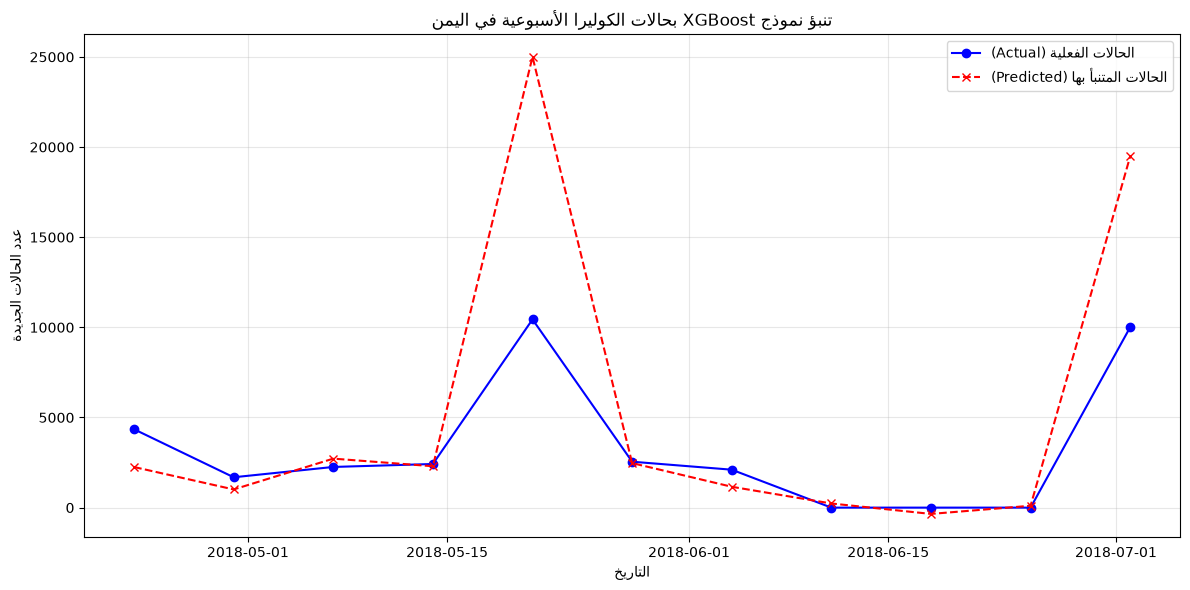

C:\Users\TAHA\AppData\Local\Temp\ipykernel_1216\1640969325.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


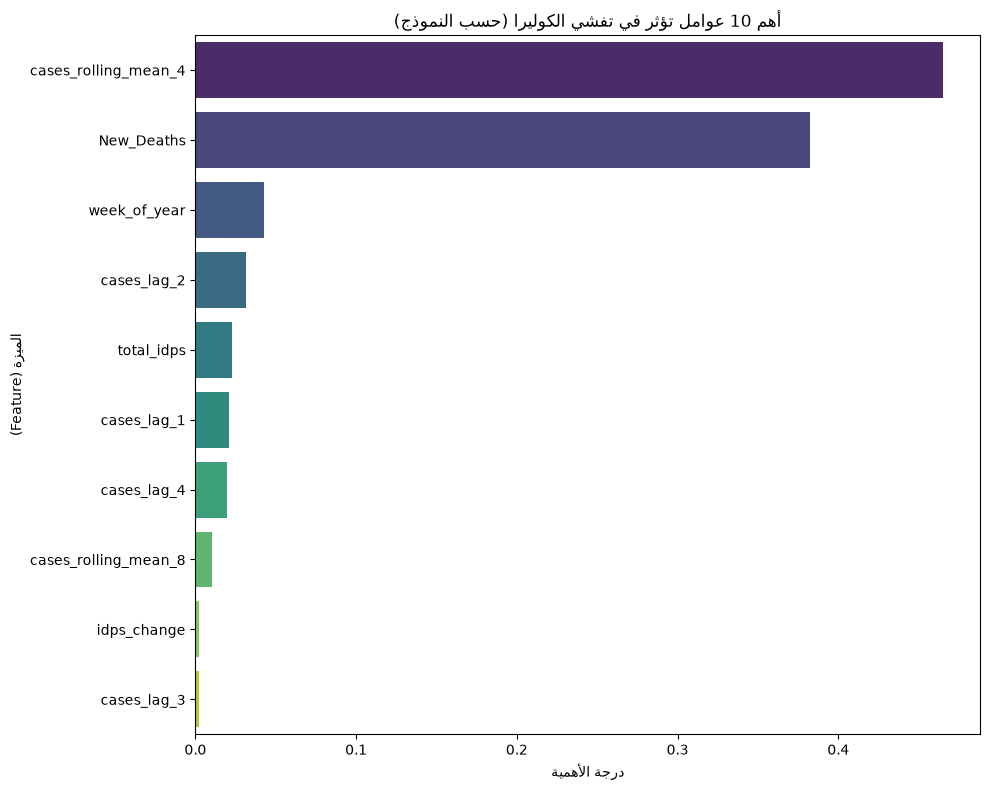


=== ترتيب أهم 5 عوامل تسبب تفشي الكوليرا ===
             Feature  Importance
cases_rolling_mean_4    0.464907
          New_Deaths    0.382076
        week_of_year    0.042635
         cases_lag_2    0.031430
          total_idps    0.022763


In [26]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# 1. تحميل البيانات وتحديد المتغيرات
# ============================================
df = pd.read_csv('final_features.csv')
df['Date'] = pd.to_datetime(df['Date'])

# المتغير المستهدف (Target): عدد الحالات الجديدة
target = 'New_Cases'

# المتغيرات المستقلة (Features): كل الأعمدة عدا التاريخ، الحالات التراكمية، والوفيات التراكمية
features_to_drop = ['Date', 'Cases', 'Deaths', 'CFR (%)', 'Attack Rate (per 1000)']
features = [col for col in df.columns if col not in features_to_drop and col != target]

X = df[features]
y = df[target]

# ملاحظة: أول 4 صفوف ستكون قيمها 0 بسبب الـ Lag، سنحذفها لتجنب التشويش على النموذج
X = X.iloc[4:]
y = y.iloc[4:]
dates = df['Date'].iloc[4:]

print(f"عدد الميزات المستخدمة: {len(features)}")
print(f"الميزات هي: {features}")

# ============================================
# تنظيف الميزات وتجهيزها لنموذج XGBoost
# ============================================

# استبعاد أعمدة التاريخ النصية من ميزات النموذج
text_columns = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("الأعمدة النصية المكتشفة:", text_columns)

# حذف الأعمدة النصية غير المجهزة
X = X.drop(columns=text_columns)

# تحديث قائمة الميزات بعد الحذف
features = X.columns.tolist()

# التأكد من أن جميع الميزات أصبحت رقمية
print("\nأنواع البيانات بعد التنظيف:")
print(X.dtypes)

print("\nعدد الميزات النهائية:", len(features))
print("✅ البيانات جاهزة للتدريب")


# ============================================
# 2. التقسيم الزمني (Time-Based Split)
# ============================================
# سنستخدم 80% من البيانات للتدريب، و 20% الأخيرة للاختبار
split_index = int(len(X) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
dates_test = dates.iloc[split_index:]

print(f"\nحجم بيانات التدريب: {len(X_train)} أسبوع")
print(f"حجم بيانات الاختبار: {len(X_test)} أسبوع")

# ============================================
# 3. بناء وتدريب نموذج XGBoost
# ============================================
# نستخدم XGBRegressor لأننا نتنبأ برقم مستمر (عدد الحالات)
model = xgb.XGBRegressor(
    n_estimators=100,       # عدد الأشجار
    learning_rate=0.1,      # معدل التعلم
    max_depth=4,            # عمق الشجرة (نمنع التعقيد الزائد Overfitting)
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

# تدريب النموذج
model.fit(X_train, y_train)
print("\n✅ تم تدريب النموذج بنجاح!")

# ============================================
# 4. التقييم (Evaluation)
# ============================================
y_pred = model.predict(X_test)

# حساب مقاييس الخطأ
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n=== نتائج تقييم النموذج ===")
print(f"متوسط الخطأ المطلق (MAE): {mae:.2f} حالة")
print(f"جذر متوسط مربع الخطأ (RMSE): {rmse:.2f} حالة")
print("💡 تفسير MAE: في المتوسط، تنبؤاتنا تخطئ بـ {:.0f} حالة أسبوعياً.".format(mae))

# ============================================
# 5. رسم النتائج (التنبؤ مقابل الواقع)
# ============================================
plt.figure(figsize=(12, 6))
plt.plot(dates_test, y_test, label='الحالات الفعلية (Actual)', color='blue', marker='o')
plt.plot(dates_test, y_pred, label='الحالات المتنبأ بها (Predicted)', color='red', marker='x', linestyle='--')
plt.title('تنبؤ نموذج XGBoost بحالات الكوليرا الأسبوعية في اليمن')
plt.xlabel('التاريخ')
plt.ylabel('عدد الحالات الجديدة')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================
# 6. تحليل أهمية الميزات (Feature Importance) - "الأهم للسياق اليمني"
# ============================================
importance = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('أهم 10 عوامل تؤثر في تفشي الكوليرا (حسب النموذج)')
plt.xlabel('درجة الأهمية')
plt.ylabel('الميزة (Feature)')
plt.tight_layout()
plt.show()

print("\n=== ترتيب أهم 5 عوامل تسبب تفشي الكوليرا ===")
print(feature_importance_df.head(5).to_string(index=False))

In [28]:
# ============================================
# تحويل التنبؤات إلى نظام إنذار مبكر (Alert System)
# ============================================

# لنفترض أننا نحدد "العتبة" (Threshold) بناءً على متوسط الحالات في فترة الهدوء
# أو يمكننا استخدام النسبة المئوية (مثلاً: إذا زاد التنبؤ عن 80% من أعلى رقم تاريخي)
threshold_yellow = 5000  # إنذار أصفر: تأهب
threshold_red = 15000    # إنذار أحمر: تفشي حاد

def get_alert_level(predicted_cases):
    if predicted_cases >= threshold_red:
        return "🔴 أحمر (تفشي حاد - تدخل فوري)"
    elif predicted_cases >= threshold_yellow:
        return "🟡 أصفر (تأهب - مراقبة مكثفة)"
    else:
        return "🟢 أخضر (وضع طبيعي)"

# تطبيق على آخر أسبوع في بيانات الاختبار
last_prediction = y_pred[-1]
alert_status = get_alert_level(last_prediction)

print(f"\n=== تقرير الإنذار المبكر للأسبوع القادم ===")
print(f"عدد الحالات المتوقع: {last_prediction:.0f} حالة")
print(f"مستوى الإنذار: {alert_status}")
print(f"الإجراء المقترح: {'تجهيز فرق الاستجابة السريعة وتوزيع الكلور' if 'أحمر' in alert_status else 'مراقبة مصادر المياه'}")


=== تقرير الإنذار المبكر للأسبوع القادم ===
عدد الحالات المتوقع: 19481 حالة
مستوى الإنذار: 🔴 أحمر (تفشي حاد - تدخل فوري)
الإجراء المقترح: تجهيز فرق الاستجابة السريعة وتوزيع الكلور


In [27]:
import joblib

# حفظ النموذج
joblib.dump(model, 'cholera_model.pkl')
print("\n✅ تم حفظ النموذج في: cholera_model.pkl")

# حفظ قائمة الميزات (مهم جداً لضمان تطابق الميزات عند التنبؤ)
joblib.dump(features, 'features_list.pkl')
print("✅ تم حفظ قائمة الميزات في: features_list.pkl")


✅ تم حفظ النموذج في: cholera_model.pkl
✅ تم حفظ قائمة الميزات في: features_list.pkl
